In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("datasets/insurance.csv")
print("Shape:",df.shape)
print("Information")
print(df.info())
print("Heading")
print(df.head())
print("Description")
print(df.describe())


Shape: (1338, 7)
Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
Heading
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Description
               age          bmi     childr

In [3]:
#now to see missing values
print("\n missing values")
print(df.isnull().sum())


 missing values
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [4]:
#now to see duplicates
print("\n duplicates:")
print(df.duplicated().sum())


 duplicates:
1


In [5]:
#now to inspect the duplicate

df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [6]:
#removing duplicates
print(df.shape)
print(df.duplicated().sum())
df[df.duplicated(keep=False)]
df1=df.drop_duplicates()
print(df1.shape)
print(df1.duplicated().sum())

(1338, 7)
1
(1337, 7)
0


In [7]:
#now we have to check the next
print(df1.dtypes)

#this is to identify the datatypes of all columns


age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [8]:
df1.nunique()

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

In [9]:
print(df1.head(25))

    age     sex     bmi  children smoker     region      charges
0    19  female  27.900         0    yes  southwest  16884.92400
1    18    male  33.770         1     no  southeast   1725.55230
2    28    male  33.000         3     no  southeast   4449.46200
3    33    male  22.705         0     no  northwest  21984.47061
4    32    male  28.880         0     no  northwest   3866.85520
5    31  female  25.740         0     no  southeast   3756.62160
6    46  female  33.440         1     no  southeast   8240.58960
7    37  female  27.740         3     no  northwest   7281.50560
8    37    male  29.830         2     no  northeast   6406.41070
9    60  female  25.840         0     no  northwest  28923.13692
10   25    male  26.220         0     no  northeast   2721.32080
11   62  female  26.290         0    yes  southeast  27808.72510
12   23    male  34.400         0     no  southwest   1826.84300
13   56  female  39.820         0     no  southeast  11090.71780
14   27    male  42.130  

In [10]:
print(df1["children"].head())

0    0
1    1
2    3
3    0
4    0
Name: children, dtype: int64


In [11]:
print("\nchildren unique values")
print(df1["children"].unique())
print("\nregion uniques values")
print(df1["region"].unique())
print("\n categories of smoke")
print(df1["smoker"].unique())
print("\n unique sex values")
print(df1["sex"].unique())


children unique values
[0 1 3 2 5 4]

region uniques values
['southwest' 'southeast' 'northwest' 'northeast']

 categories of smoke
['yes' 'no']

 unique sex values
['female' 'male']


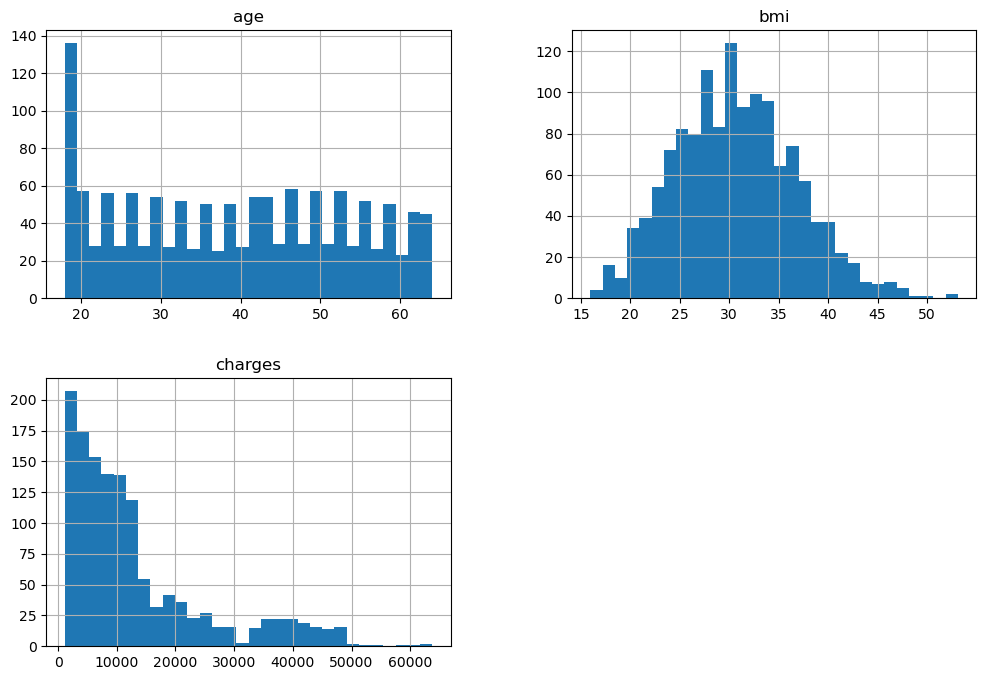

In [12]:
#look at this data now
import matplotlib.pyplot as plt 
df1[["age","bmi","charges"]].hist(figsize=(12,8),bins=30)
plt.show()

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'charges'}>],
       [<Axes: title={'center': 'bmi'}>, <Axes: >]], dtype=object)

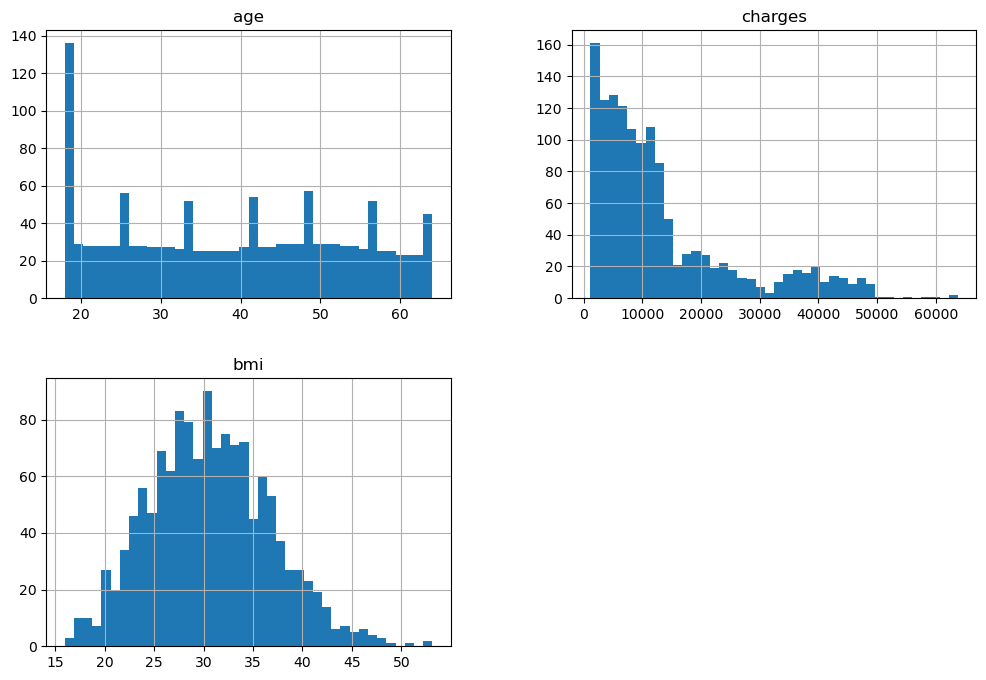

In [13]:
import matplotlib.pyplot as plt

df1[["age","charges","bmi"]].hist(figsize=(12,8),bins=40)

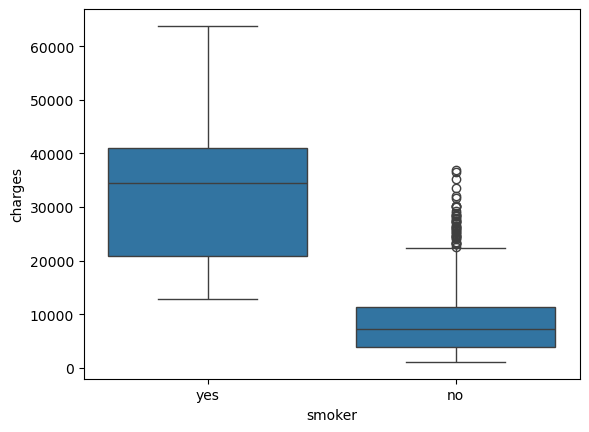

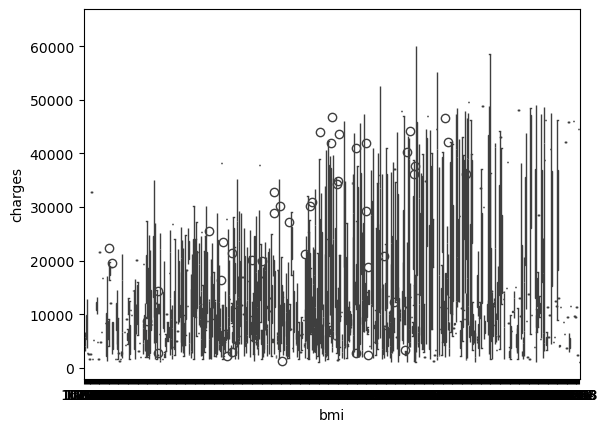

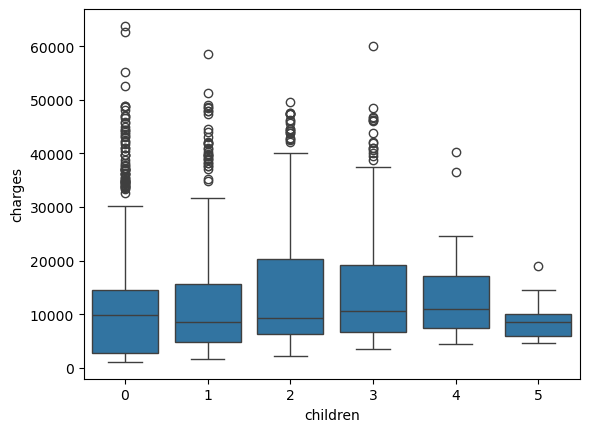

In [14]:
#Next analysis: smoker vs charges

import seaborn as sns

sns.boxplot(data=df1,x="smoker",y="charges")
plt.show()

sns.boxplot(data=df1,x="bmi",y="charges")
plt.show()

sns.boxplot(data=df1,x="children",y="charges")
plt.show()

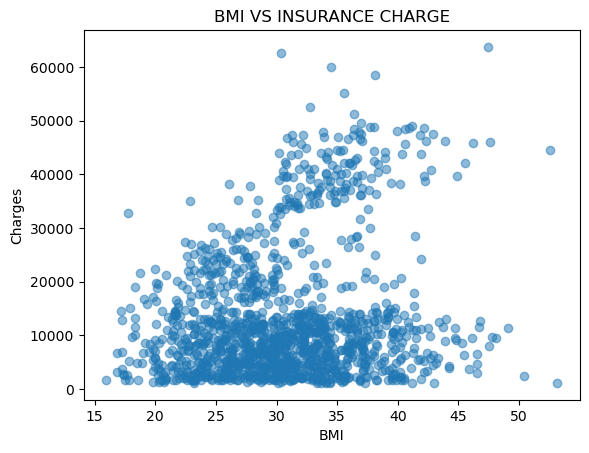

In [15]:

plt.scatter(df1["bmi"],df1["charges"],alpha=0.5)

plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("BMI VS INSURANCE CHARGE")

plt.show()

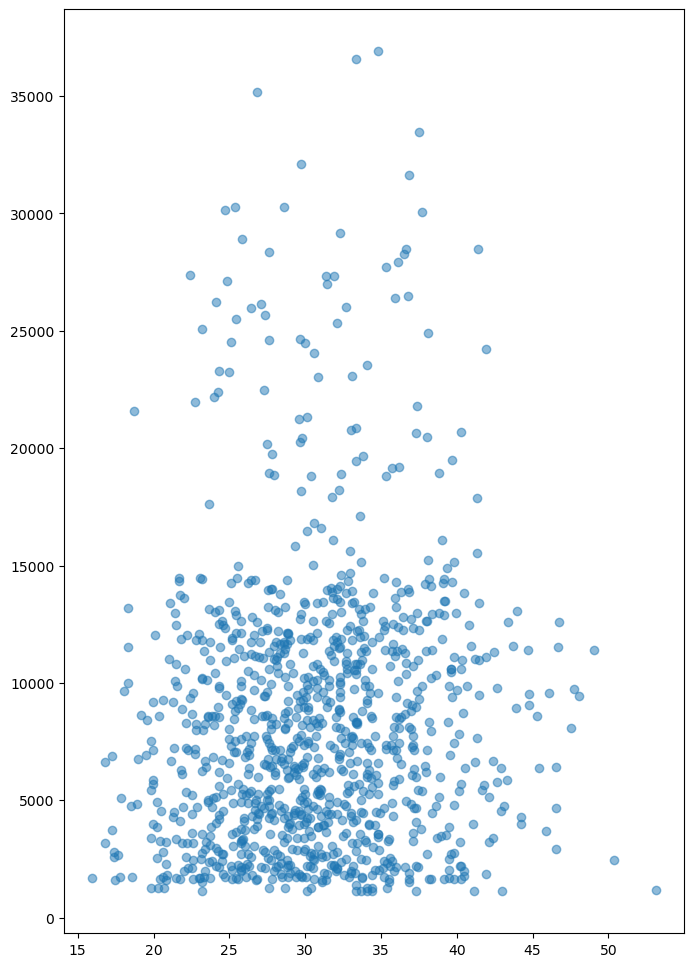

In [16]:
#BMI have some relationship with charges
#now let's visualize it with Smokers, non_smokers , BMI and charges.

smokers=df1[df1["smoker"]=="yes"]
non_smoker=df1[df1["smoker"]=="no"]

plt.figure(figsize=(8,12))

plt.scatter(non_smoker["bmi"],non_smoker["charges"],alpha=0.5,label="Non smoker")

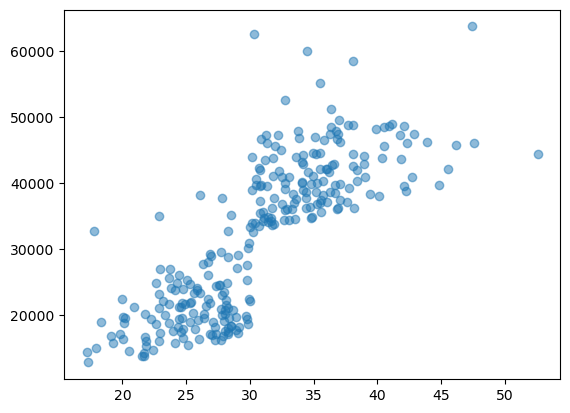

In [17]:
plt.scatter(smokers["bmi"],smokers["charges"],alpha=0.5,label="Smokers")

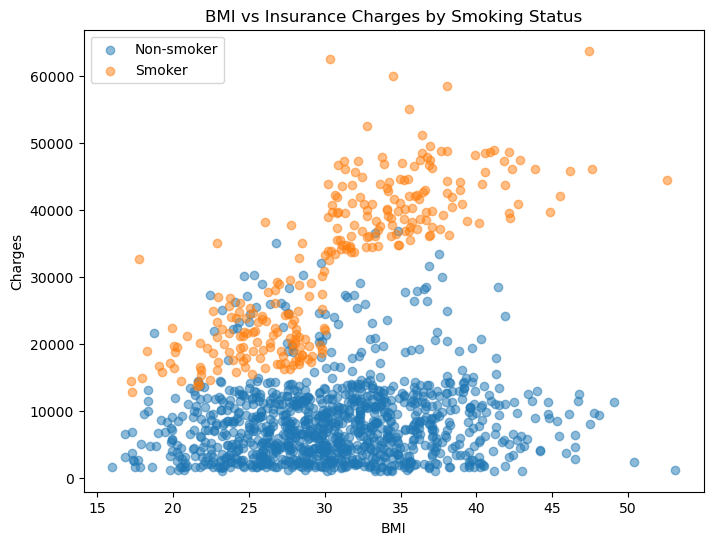

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(
    non_smoker["bmi"],
    non_smoker["charges"],
    alpha=0.5,
    label="Non-smoker"
)

plt.scatter(
    smokers["bmi"],
    smokers["charges"],
    alpha=0.5,
    label="Smoker"
)

plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("BMI vs Insurance Charges by Smoking Status")
plt.legend()

plt.show()

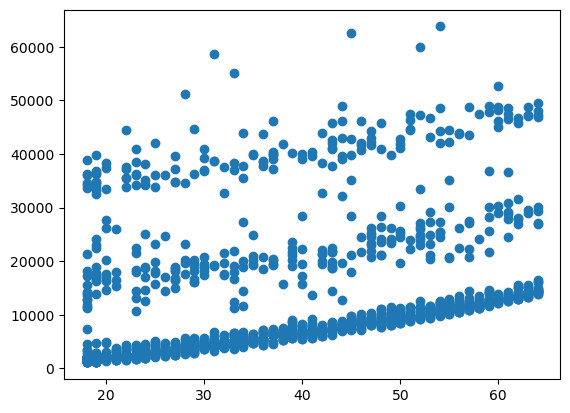

In [19]:
#let's investigate Age-Charges

plt.scatter(df1["age"],df1["charges"],label="Age-charges")
plt.show()

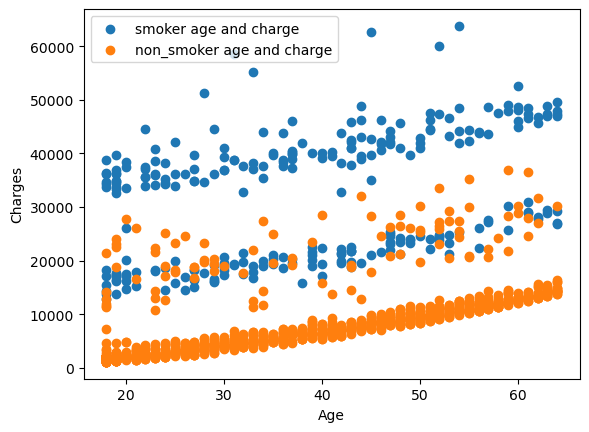

In [20]:
#relation on Age charge and smoking

smoker=df1[df1["smoker"]=="yes"]
non_smoker=df1[df1["smoker"]=="no"]


plt.scatter(smoker["age"],smoker["charges"],label="smoker age and charge")
plt.scatter(non_smoker["age"],non_smoker["charges"],label="non_smoker age and charge")

plt.xlabel("Age")
plt.ylabel("Charges")
plt.legend()
plt.show()

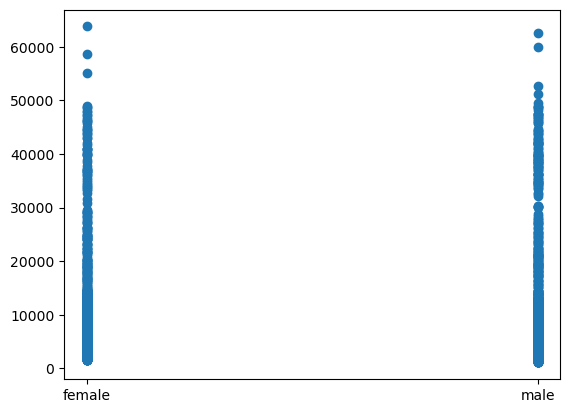

In [21]:
#Relation between sex and charge

plt.scatter(df1["sex"],df1["charges"],label="Sex and charge")
plt.show()



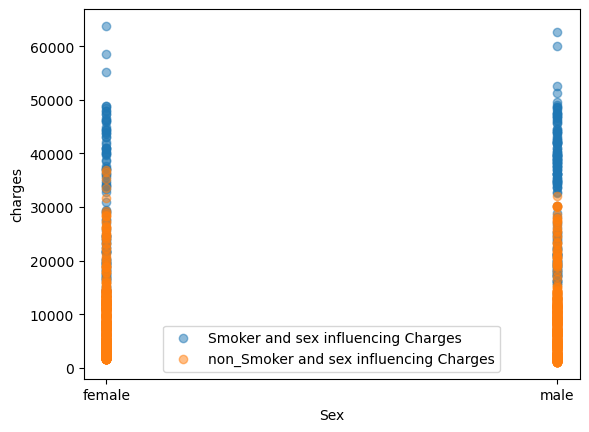

In [22]:
smoker=df1[df1["smoker"]=="yes"]
non_smoker=df1[df1["smoker"]=="no"]

plt.scatter(smoker["sex"],smoker["charges"],alpha=0.5,label="Smoker and sex influencing Charges")
plt.scatter(non_smoker["sex"],non_smoker["charges"],alpha=0.5,label="non_Smoker and sex influencing Charges")

plt.xlabel("Sex")
plt.ylabel("charges")
plt.legend()
plt.show()

In [23]:
#let's define x and y
#x - training data 
#y - target variable

y=df1['charges']
print(y.shape)

x=df1.drop('charges',axis=1)
print(x.shape)

(1337,)
(1337, 6)


In [24]:
#split the dataset
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)
print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

x_train: (1069, 6)
x_test: (268, 6)
y_train: (1069,)
y_test: (268,)


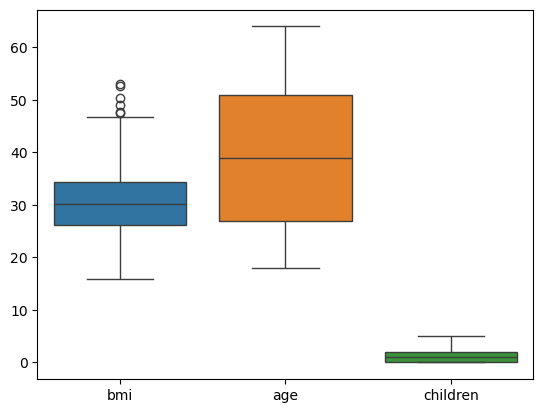

In [25]:
#invegtigate outliers
#let's use a boxplot to investigate the BMI, AGE, CHILDREN
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=x_train[['bmi','age','children']])
plt.show()



In [26]:
# now we need to investigate outliers of BMI using IQR method
#IQR=Q3-Q1
#LOWER bound=Q1-1.5*IQR
#uPPER BOUND=Q3+1.5*IQR

q1=x_train['bmi'].quantile(0.25)
q3=x_train['bmi'].quantile(0.75)
print("q1=",q1)
print("q3=",q3)

iqr=q3-q1
print("IQR value=",iqr)

lower_bound=q1-1.5*iqr
upper_bound=q3+1.5*iqr

print("lower_bound",lower_bound)
print("upper_bound",upper_bound)



q1= 26.18
q3= 34.43
IQR value= 8.25
lower_bound 13.805
upper_bound 46.805


In [27]:
# now we have to identify the total number of outliers 

lower_count=(x_train['bmi']<lower_bound).sum()
upper_count=(x_train['bmi']>upper_bound).sum()

total=lower_count+upper_count

print("lower count:",lower_count)
print("upper count:",upper_count)
print(total)

lower count: 0
upper count: 6
6


In [28]:
#let's display the BMI values
bmi_outliers=x_train[(x_train['bmi']<lower_bound) | (x_train['bmi']>upper_bound)]
print(bmi_outliers['bmi'].sort_values())

401     47.52
1088    47.74
116     49.06
847     50.38
1047    52.58
1317    53.13
Name: bmi, dtype: float64


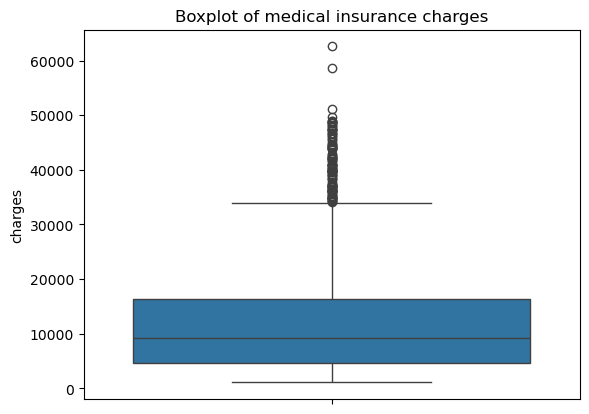

In [29]:
#let's inspect the outliers on target 

sns.boxplot(y_train)
plt.title("Boxplot of medical insurance charges")
plt.show()


In [30]:
#anywat we are retaining it for the basemodel 
#3. Next step: Categorical feature encoding
#we are using one hot encoding
#let's identify the categorical columns in training data

print(x_train[['smoker','sex','region']].nunique())
print(x_train[['smoker','sex','region']].apply(lambda column: column.unique()))

smoker    2
sex       2
region    4
dtype: int64
smoker                                       [no, yes]
sex                                     [male, female]
region    [northeast, northwest, southeast, southwest]
dtype: object


In [31]:
#creating a list for categorical and non categorical values
numerical=[x_train[['age','bmi','children']]]
print(numerical)
categorical=[x_train[['smoker','region','sex']]]
print(categorical)

[      age     bmi  children
1114   23  24.510         0
968    21  25.745         2
599    52  37.525         2
170    63  41.470         0
275    47  26.600         2
...   ...     ...       ...
1096   51  34.960         2
1131   27  45.900         2
1295   20  22.000         1
861    38  28.000         3
1127   35  35.860         2

[1069 rows x 3 columns]]
[     smoker     region     sex
1114     no  northeast    male
968      no  northeast    male
599      no  northwest  female
170      no  southeast    male
275      no  northeast  female
...     ...        ...     ...
1096    yes  northeast  female
1131     no  southwest    male
1295     no  southwest    male
861      no  southwest  female
1127     no  southeast  female

[1069 rows x 3 columns]]


     Training Data
                       |
                 ColumnTransformer
                       |
              +--------+--------+
              |                 |
              v                 v
       Numerical Features  Categorical Features
       age, bmi, children   sex, smoker, region
              |                 |
              v                 v
       StandardScaler       OneHotEncoder
              |                 |
              +--------+--------+
                       |
                       v
             Transformed Features
                       |
                       v
                Linear Regression

In [33]:
#A scikit-learn pipeline helps us ensure that consistency.
#2. First, define the feature groups
# create two Python lists: numerical and categorical.
numerical_features=['age','bmi','children']
categorical_features=['sex','smoker','region']

print("numerical-features:",numerical_features)
print("categorical_features:",categorical_features)


numerical-features: ['age', 'bmi', 'children']
categorical_features: ['sex', 'smoker', 'region']


In [34]:
#to build the column transformer
#standard scalar to numerical features and onehot encoding to categorical features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor=ColumnTransformer([('num',StandardScaler(),numerical_features),
                                ('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)])


In [35]:
#Fit and transform
x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)

print("x_train_processed:Shape:",x_train_processed.shape)
print("x_test_processed;shape:",x_test_processed.shape)

x_train_processed:Shape: (1069, 11)
x_test_processed;shape: (268, 11)


In [36]:
#Train our baseline Linear Regression model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#ML pipwline

model_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('regressor',LinearRegression())
])



In [37]:
#Train the model
model_pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', LinearRegression())])

In [38]:
#Make predictions
y_pred=model_pipeline.predict(x_test)
#display first 10 predictions

print("predicted charges:")
print(y_pred[:10])

print("actual charges:")
print(y_test.iloc[:10].values)

predicted charges:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706 13149.72235307 30446.76067941  1453.28881259
 10633.01840233 11318.94379361]
actual charges:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]


In [39]:
#2. Next step: Evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import numpy

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

# Display results 
print("Baseline Linear Regression Performance")
print("--------------------------------------") 
print(f"MAE: {mae:.2f}") 
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}") 
print(f"R²: {r2:.4f}")

Baseline Linear Regression Performance
--------------------------------------
MAE: 4177.05
MSE: 35478020.68
RMSE: 5956.34
R²: 0.8069


In [82]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [86]:
from xgboost import XGBRegressor
print("XGBoost imported successfully")

XGBoost imported successfully


In [101]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

xgb_preprocessor=ColumnTransformer(transformers=[('num','passthrough',numerical_features),
                                                 ('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)])

In [109]:
xgb_pipeline=Pipeline([('preprocessor',xgb_preprocessor),
                      ('regressor',XGBRegressor(n_estimators=300,learning_rate=0.05,max_depth=3,
                                                objective='reg:squarederror',random_state=42,n_jobs=-1))])

In [111]:
#train the xgboost model
xgb_pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None,
                              early_stopping...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=3, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=300, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [113]:
xgb_pred=xgb_pipeline.predict(x_test)

In [115]:
print("First 10 XGBoost predictions:")
print(xgb_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 XGBoost predictions:
[10904.051   6670.991  13412.419  39059.43    5436.118  12095.088
 40504.297   3856.5513  9631.499  10878.862 ]

First 10 actual values:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]


In [117]:
#evaluate the xgboost model

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
xgb_mae=mean_absolute_error(y_test,xgb_pred)
xgb_mse=mean_squared_error(y_test,xgb_pred)
xgb_rmse=np.sqrt(xgb_mse)
xgb_r2=r2_score(y_test,xgb_pred)

# Display results
print("XGBoost Model Performance")
print("-------------------------")
print(f"MAE:  {xgb_mae:.2f}")
print(f"MSE:  {xgb_mse:.2f}")
print(f"RMSE: {xgb_rmse:.2f}")
print(f"R²:   {xgb_r2:.4f}")

XGBoost Model Performance
-------------------------
MAE:  2525.94
MSE:  18542158.28
RMSE: 4306.06
R²:   0.8991


In [123]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'XGBoost'],
    'MAE': [mae, xgb_mae],
    'RMSE': [rmse, xgb_rmse],
    'R2': [r2, xgb_r2]
})

comparison = comparison.sort_values(by='RMSE')

print(comparison)

               Model          MAE         RMSE        R2
1            XGBoost  2525.940125  4306.060645  0.899094
0  Linear Regression  4177.045561  5956.342894  0.806929


In [127]:
import joblib
joblib.dump(xgb_pipeline,'xgb_model.joblib')

['xgb_model.joblib']

In [131]:
import os
print(os.path.exists('xgb_model.joblib'))

True


In [133]:
#try to load the model
import joblib
loaded_model=joblib.load('xgb_model.joblib')
print("model loaded successfully")

model loaded successfully


In [139]:
loaded_pred=loaded_model.predict(x_test)
print("Orginal model predictions")
print(xgb_pipeline.predict(x_test)[:5])
print("\nLoaded model predictions:")
print(loaded_pred[:5])

Orginal model predictions
[10904.051  6670.991 13412.419 39059.43   5436.118]

Loaded model predictions:
[10904.051  6670.991 13412.419 39059.43   5436.118]


In [3]:
import os 
print(os.getcwd())

C:\Users\prana\OneDrive\Data science\Regression\Medical_insurance_Cost_Prediction
